In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", X.shape)
print("Target Classes:", data.target_names)

Dataset Loaded Successfully!
Dataset Shape: (569, 30)
Target Classes: ['malignant' 'benign']


In [3]:
print(X.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [4]:
print(y.head())

0    0
1    0
2    0
3    0
4    0
dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)


In [6]:
model = LogisticRegression(max_iter=5000)

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [7]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("Predicted Values:")
print(y_pred[:10])

Actual Values:
[1 0 0 1 1 0 0 0 1 1]
Predicted Values:
[1 0 0 1 1 0 0 0 1 1]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.956140350877193
Accuracy Percentage: 95.6140350877193 %


In [9]:
precision = precision_score(y_test, y_pred)

print("Precision:", precision)

Precision: 0.9459459459459459


In [10]:
recall = recall_score(y_test, y_pred)

print("Recall:", recall)

Recall: 0.9859154929577465


In [11]:
f1 = f1_score(y_test, y_pred)

print("F1-Score:", f1)

F1-Score: 0.9655172413793104


In [12]:
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

print(results)

      Metric     Score
0   Accuracy  0.956140
1  Precision  0.945946
2     Recall  0.985915
3   F1-Score  0.965517


In [13]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[39  4]
 [ 1 70]]


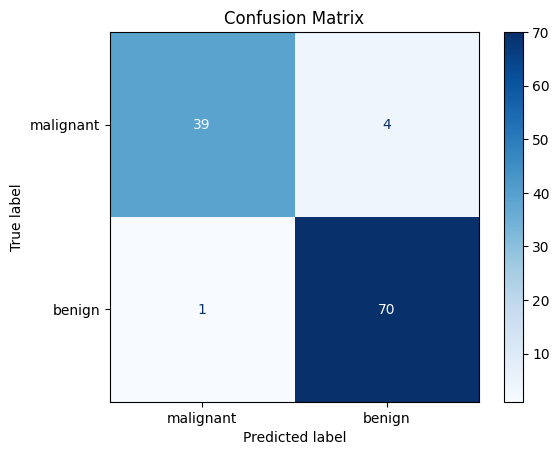

In [16]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png")
plt.show()

In [15]:
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

